# 02 · The surrogate model: a Gaussian process, visualized

**What you will learn.** What a Gaussian process (GP) is, what the *kernel*, its *lengthscale*, its *variance* and the *noise* term do, how a GP turns observations into predictions with uncertainty, and how its hyperparameters can be fitted from data (and when that goes wrong).

**Background in two sentences.** A GP is a distribution over functions: before seeing any data it says "the function is smooth in a way described by a kernel `k(x, x')`", and after seeing data it keeps only the functions that agree with the observations. The prediction at a new point is therefore a *mean* and a *variance*, which is exactly what Bayesian optimization needs (notebook 01).

In this notebook we use OpenBO's `GPScratch` and its kernel functions, and we also compute the posterior by hand once, so that nothing is a black box. It runs in about 10 seconds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from openbo.models.gp_scratch import GPScratch
from openbo.models.kernels import rbf_kernel, matern52_kernel

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
grid = np.linspace(0.0, 1.0, 200)[:, None]          # test inputs, shape (n, d) with d = 1

## 1. The kernel: what "smooth" means

The kernel `k(x, x')` is the prior covariance between the function values at `x` and `x'`: close inputs get a high value (their outputs move together), distant inputs a value near zero. OpenBO provides two: **RBF** (very smooth, infinitely differentiable) and **Matérn-5/2** (a little rougher, the usual default for BO). Both have two knobs:

- the **lengthscale** `ℓ`: how far apart two inputs must be before they stop being related;
- the **variance** `σ²`: the vertical scale of the function.

First, the shape of `k(0.5, x)` for a few lengthscales.

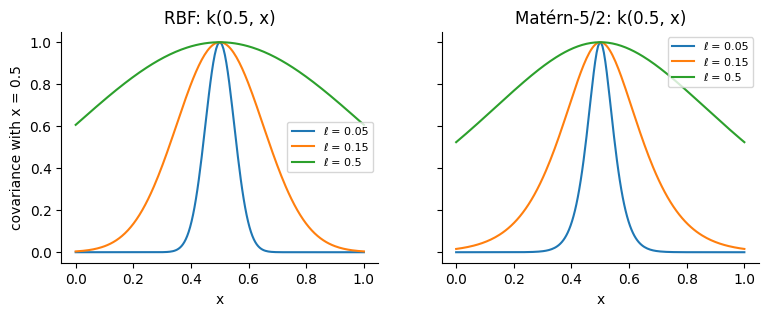

In [2]:
x0 = np.array([[0.5]])
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, (name, kernel) in zip(axes, (("RBF", rbf_kernel), ("Matérn-5/2", matern52_kernel))):
    for ell in (0.05, 0.15, 0.5):
        ax.plot(grid[:, 0], kernel(x0, grid, lengthscale=ell, variance=1.0)[0], label=f"ℓ = {ell}")
    ax.set_title(f"{name}: k(0.5, x)"); ax.set_xlabel("x"); ax.legend(fontsize=8)
axes[0].set_ylabel("covariance with x = 0.5")
plt.show()

A short lengthscale means "forget quickly": only very close points inform each other. A long one means "the function varies slowly". Now the more telling picture: draw random functions **from the prior**, i.e. before any data. A draw from a GP is a draw from a multivariate normal whose covariance matrix is the kernel evaluated on a grid.

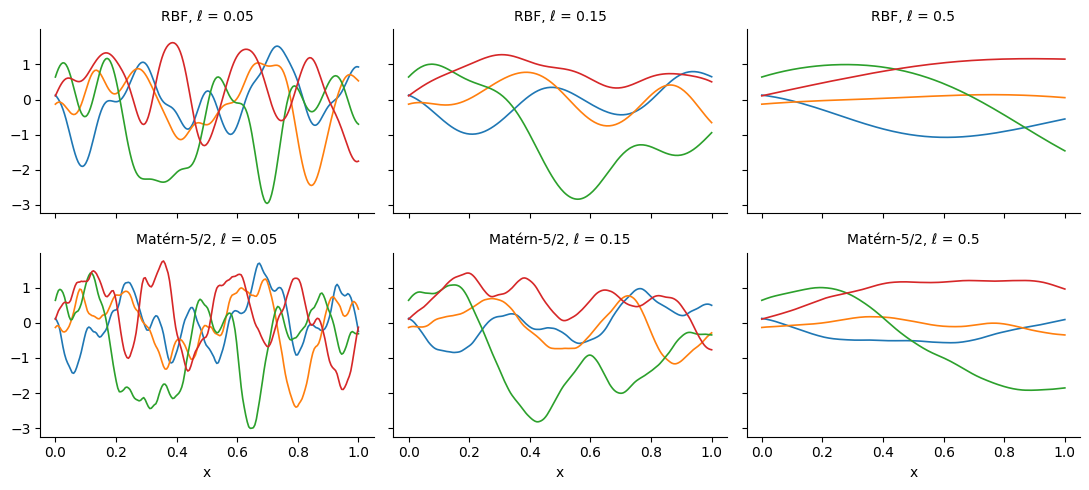

In [3]:
def prior_samples(kernel, ell, n=4, variance=1.0, seed=0):
    K = kernel(grid, grid, lengthscale=ell, variance=variance) + 1e-8 * np.eye(len(grid))   # tiny jitter for stability
    L = np.linalg.cholesky(K)
    return (L @ np.random.default_rng(seed).standard_normal((len(grid), n)))

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey=True)
for row, (name, kernel) in enumerate((("RBF", rbf_kernel), ("Matérn-5/2", matern52_kernel))):
    for col, ell in enumerate((0.05, 0.15, 0.5)):
        axes[row, col].plot(grid[:, 0], prior_samples(kernel, ell), lw=1.2)
        axes[row, col].set_title(f"{name}, ℓ = {ell}", fontsize=10)
for ax in axes[1]: ax.set_xlabel("x")
plt.tight_layout(); plt.show()

Reading the grid: along each row the functions get slower as `ℓ` grows; along each column, the Matérn draws are visibly rougher than the RBF ones. **The kernel is your assumption about the objective.** If the real function is rougher or smoother than the kernel allows, the GP will be over- or under-confident.

## 2. Conditioning on data

Take six noise-free observations of a smooth function and let the GP learn from them. With the observations `X`, `y`, the kernel matrix `K = k(X, X) + noise·I` and the cross-covariance `K* = k(X, x*)`, the posterior at a new point `x*` is Gaussian with

```
mean(x*) = K*ᵀ K⁻¹ y
var(x*)  = k(x*, x*) − K*ᵀ K⁻¹ K*
```

`GPScratch.posterior` computes exactly this (using a Cholesky factorization instead of an explicit inverse). To prove it, we compute it by hand as well. We set `standardize_targets=False` so that `GPScratch` works in the original units and the two are directly comparable.

In [4]:
def g(x):                                   # a smooth function to learn
    return np.sin(7 * np.asarray(x, dtype=float)) + 0.5 * np.asarray(x, dtype=float)

rng = np.random.default_rng(1)
x_obs = np.sort(rng.uniform(0.05, 0.95, 6))
y_obs = g(x_obs)

ell, var, noise = 0.2, 1.0, 1e-6
gp = GPScratch(lengthscale=ell, variance=var, noise=noise, kernel_type="rbf", standardize_targets=False)
gp.fit(x_obs[:, None], y_obs)
mean, variance = gp.posterior(grid)

# The same thing by hand.
X = x_obs[:, None]
K = rbf_kernel(X, X, ell, var) + noise * np.eye(len(X))
Ks = rbf_kernel(X, grid, ell, var)
mean_hand = Ks.T @ np.linalg.solve(K, y_obs)
cov_hand = rbf_kernel(grid, grid, ell, var) - Ks.T @ np.linalg.solve(K, Ks)
print("max |mean difference| :", float(np.abs(mean - mean_hand).max()))
print("max |variance difference|:", float(np.abs(variance - np.diag(cov_hand)).max()))

max |mean difference| : 3.903378854808182e-06
max |variance difference|: 1.2746170778843435e-06


They agree to about six digits (the remaining differences of order 1e-6 come from a tiny jitter that `GPScratch` adds to the diagonal for stability). The covariance matrix we just built also lets us draw **posterior samples**: functions that are consistent with the data.

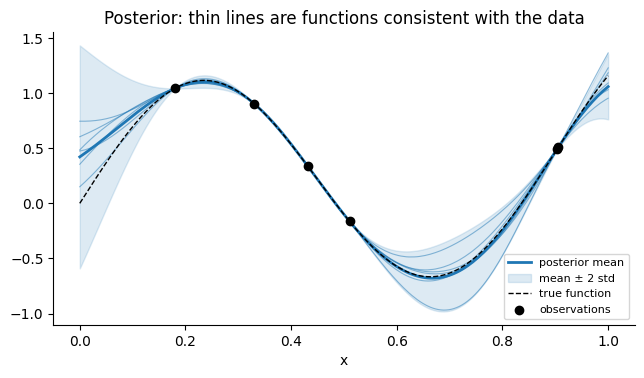

In [5]:
L = np.linalg.cholesky(cov_hand + 1e-8 * np.eye(len(grid)))
samples = mean_hand[:, None] + L @ np.random.default_rng(0).standard_normal((len(grid), 6))
std = np.sqrt(variance)

plt.figure(figsize=(7.5, 3.8))
plt.plot(grid[:, 0], samples, color="C0", lw=0.8, alpha=0.5)
plt.plot(grid[:, 0], mean, color="C0", lw=2, label="posterior mean")
plt.fill_between(grid[:, 0], mean - 2 * std, mean + 2 * std, color="C0", alpha=0.15, label="mean ± 2 std")
plt.plot(grid[:, 0], g(grid[:, 0]), "k--", lw=1, label="true function")
plt.scatter(x_obs, y_obs, c="k", zorder=5, label="observations")
plt.xlabel("x"); plt.legend(fontsize=8); plt.title("Posterior: thin lines are functions consistent with the data"); plt.show()

Every thin line passes through the six observations (the noise is almost zero), and they fan out between them: that spread *is* the uncertainty. Near the data the band is tight, and it widens in the gaps and towards the ends. This honest uncertainty is what the acquisition function exploits.

## 3. The lengthscale and the noise change what the GP believes

Same data, three lengthscales. A lengthscale that is too short makes the GP treat every point as isolated (the mean falls back to the prior mean 0 between observations and the band is wide); one that is too long over-smooths and is overconfident where the function actually bends.

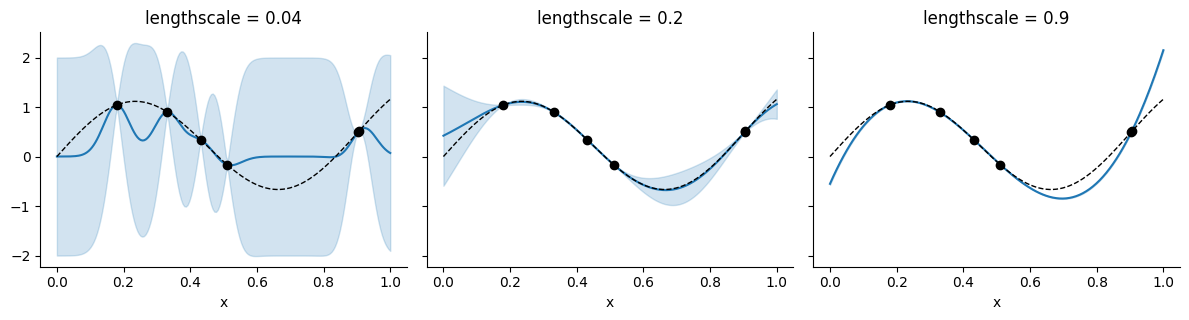

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for ax, ell_i in zip(axes, (0.04, 0.2, 0.9)):
    gp_i = GPScratch(lengthscale=ell_i, variance=1.0, noise=1e-6, kernel_type="rbf", standardize_targets=False)
    gp_i.fit(x_obs[:, None], y_obs); mu, va = gp_i.posterior(grid); sd = np.sqrt(va)
    ax.plot(grid[:, 0], mu, color="C0"); ax.fill_between(grid[:, 0], mu - 2 * sd, mu + 2 * sd, color="C0", alpha=0.2)
    ax.plot(grid[:, 0], g(grid[:, 0]), "k--", lw=1); ax.scatter(x_obs, y_obs, c="k", zorder=5)
    ax.set_title(f"lengthscale = {ell_i}"); ax.set_xlabel("x")
plt.tight_layout(); plt.show()

The **noise** term (`noise`) is the variance of the observation noise added to the diagonal of `K`. With real measurements you never see the exact function value. Below the observations are noisy (standard deviation 0.15). A GP told "no noise" is forced to pass through every point and wiggles; one told the true noise level averages it out.

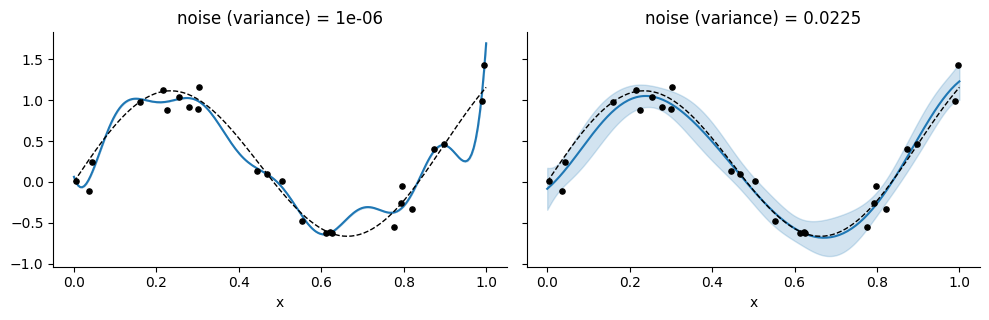

In [7]:
rng2 = np.random.default_rng(7)
x_n = np.sort(rng2.uniform(0.0, 1.0, 25))
y_n = g(x_n) + 0.15 * rng2.standard_normal(25)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, nz in zip(axes, (1e-6, 0.15 ** 2)):
    gp_n = GPScratch(lengthscale=0.15, variance=1.0, noise=nz, kernel_type="rbf", standardize_targets=False)
    gp_n.fit(x_n[:, None], y_n); mu, va = gp_n.posterior(grid); sd = np.sqrt(va)
    ax.plot(grid[:, 0], mu, color="C0"); ax.fill_between(grid[:, 0], mu - 2 * sd, mu + 2 * sd, color="C0", alpha=0.2)
    ax.plot(grid[:, 0], g(grid[:, 0]), "k--", lw=1); ax.scatter(x_n, y_n, c="k", s=14, zorder=5)
    ax.set_title(f"noise (variance) = {nz:.0e}" if nz < 1e-3 else f"noise (variance) = {nz:.4f}"); ax.set_xlabel("x")
plt.tight_layout(); plt.show()

## 4. Fitting the hyperparameters from data

Rather than guessing `ℓ` and `σ²`, we can choose them to make the data as probable as possible: maximize the **marginal likelihood** `p(y | X, ℓ, σ²)` (equivalently, minimize its negative logarithm). In `GPScratch` this is `optimize_hyperparameters=True`, and it is what OpenBO's BO loops do by default on real problems.

We write the objective ourselves, for the Matérn-5/2 kernel, and plot it as a function of the lengthscale for two datasets drawn from the objective of notebook 01: 3 points and 12 points. We standardize `y` and fix the variance at 1, as `GPScratch` does internally by default.

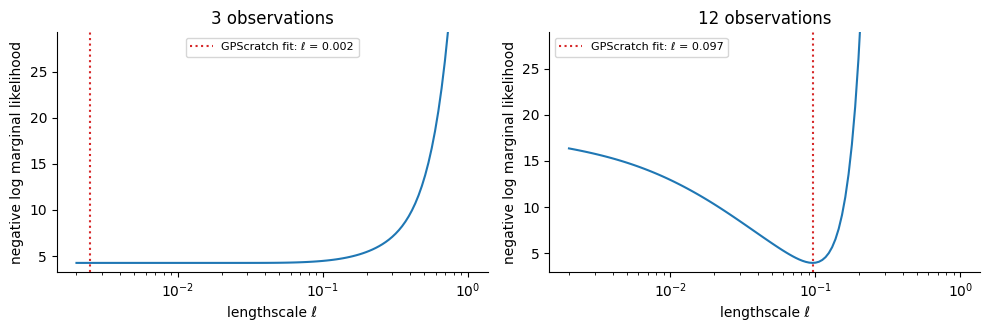

In [8]:
def f01(x):                                 # the objective of notebook 01
    x = np.asarray(x, dtype=float)
    return 0.8 * np.exp(-((x - 0.25) / 0.08) ** 2) + np.exp(-((x - 0.75) / 0.1) ** 2) + 0.15 * np.sin(25 * x)

def neg_log_marginal_likelihood(x, y, ell, variance=1.0, noise=1e-6):
    y = (y - y.mean()) / y.std()
    X = x[:, None]
    K = matern52_kernel(X, X, ell, variance) + (noise + 1e-10) * np.eye(len(x))
    L = np.linalg.cholesky(K)
    a = np.linalg.solve(L.T, np.linalg.solve(L, y))
    return 0.5 * y @ a + np.log(np.diag(L)).sum() + 0.5 * len(x) * np.log(2 * np.pi)

x3 = np.random.default_rng(3).uniform(0.0, 1.0, 3)
x12 = np.sort(np.random.default_rng(5).uniform(0.0, 1.0, 12))
ells = np.geomspace(0.002, 1.0, 120)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
fitted = {}
for ax, (label, xs) in zip(axes, (("3 observations", x3), ("12 observations", x12))):
    ys = f01(xs)
    curve = np.array([neg_log_marginal_likelihood(xs, ys, e) for e in ells])
    ax.plot(ells, curve)
    ax.set_ylim(curve.min() - 1.0, curve.min() + 25.0)       # zoom on the interesting part; the curve shoots up for long lengthscales
    gp_fit = GPScratch(kernel_type="matern52", optimize_hyperparameters=True, optimizer_seed=0)
    gp_fit.fit(xs[:, None], ys)
    fitted[label] = (xs, ys, gp_fit)
    ax.axvline(float(gp_fit.lengthscale[0]), color="C3", ls=":", label=f"GPScratch fit: ℓ = {float(gp_fit.lengthscale[0]):.3f}")
    ax.set_xscale("log"); ax.set_xlabel("lengthscale ℓ"); ax.set_ylabel("negative log marginal likelihood")
    ax.set_title(label); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

With **12 observations** the curve has a clear valley (around ℓ ≈ 0.1) and the optimizer finds it. With **3 observations** the curve is flat for every lengthscale shorter than the spacing between the points: such a GP treats all three points as unrelated, which explains the data exactly as well as any other short lengthscale, so the data cannot say which one is right, and the optimizer lands anywhere on the plateau (here at about 0.002). That is why notebook 01 fixed the lengthscale for its first iterations. The consequence is visible below.

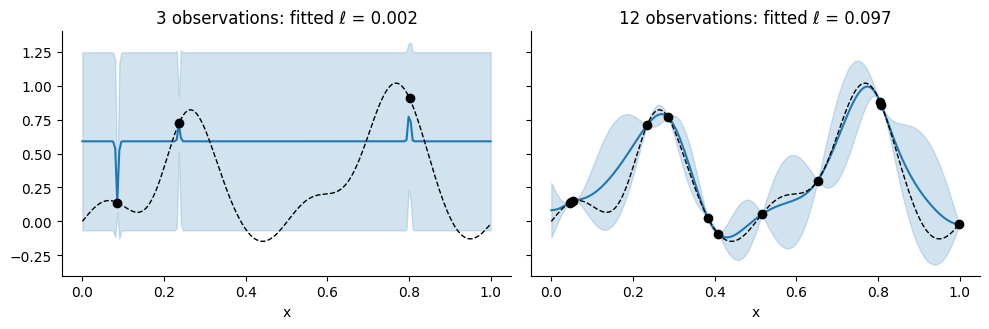

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (label, (xs, ys, gp_fit)) in zip(axes, fitted.items()):
    mu, va = gp_fit.posterior(grid); sd = np.sqrt(va)
    ax.plot(grid[:, 0], mu, color="C0"); ax.fill_between(grid[:, 0], mu - 2 * sd, mu + 2 * sd, color="C0", alpha=0.2)
    ax.plot(grid[:, 0], f01(grid[:, 0]), "k--", lw=1); ax.scatter(xs, ys, c="k", zorder=5)
    ax.set_title(f"{label}: fitted ℓ = {float(gp_fit.lengthscale[0]):.3f}"); ax.set_xlabel("x")
plt.tight_layout(); plt.show()

With 3 points the fitted GP is useless as a guide (flat mean, spikes at the data), with 12 it follows the function. In practice: **use a reasonable number of initial points before fitting hyperparameters** (OpenBO defaults to 5 in `run_bo_scratch`), or fix the lengthscale from prior knowledge.

## Takeaways

- A GP = a kernel (your smoothness assumption) + data. Its prediction is a mean and a variance, and its uncertainty grows away from the data.
- `lengthscale` controls how fast the function varies, `variance` its vertical scale, `noise` how much to trust single observations.
- Hyperparameters can be fitted by maximizing the marginal likelihood, but only when there is enough data to identify them.

**`GPScratch` cheat sheet**

| argument | meaning | default |
|---|---|---|
| `kernel_type` | `"rbf"` or `"matern52"` | `"matern52"` |
| `lengthscale` | a scalar, or one value per input dimension (ARD) | `1.0` |
| `variance` | kernel variance (in standardized units if `standardize_targets`) | `1.0` |
| `noise` | observation noise variance | `1e-6` |
| `standardize_targets` | subtract the mean and divide by the std of `y` before fitting | `True` |
| `optimize_hyperparameters` | fit `lengthscale` and `variance` by marginal likelihood | `False` (BO loops set it to `True`) |

**Next:** `03_ei_ucb_pi` uses this posterior to decide where to evaluate next.